# 2D Heat Equation on a Circular Disk via Finite Differences

We solve the unsteady 2D heat equation

$$
u_t = \alpha \left(u_{xx} + u_{yy}\right)
$$

on a Cartesian grid covering

$$
(x, y) \in [-1.5, 1.5] \times [-1.5, 1.5], \qquad \alpha = 1,
$$

with the circular disk

$$
x^2 + y^2 \le 1.
$$

We use an explicit finite-difference scheme on a `300 x 300` grid. The disk is embedded in the square domain, and points outside the disk are used to impose the boundary values at each time step.

## Boundary Conditions

The boundary of the disk is held at different temperatures on the left and right halves:

- Left half of the disk boundary: $u = 1$ for $x < 0$
- Right half of the disk boundary: $u = 2$ for $x \ge 0$

In the implementation below, this is imposed by resetting all points outside the disk at the start of each step to those fixed values. Interior points adjacent to the outside therefore feel the boundary through the finite-difference stencil.

## Initial Conditions

We simulate two cases:

1. Zero initial condition inside the disk: $u(x,y,0) = 0$
2. Signed initial condition inside the disk: top half $u = -1$ for $y > 0$, bottom half $u = 1$ for $y \le 0$

## Numerical Scheme

For interior grid points we use the explicit update

$$
u_{i,j}^{n+1} = u_{i,j}^n + \alpha \Delta t
\left(
\frac{u_{i+1,j}^n - 2u_{i,j}^n + u_{i-1,j}^n}{\Delta x^2}
+
\frac{u_{i,j+1}^n - 2u_{i,j}^n + u_{i,j-1}^n}{\Delta y^2}
\right).
$$

For stability on a uniform grid with $\Delta x = \Delta y$, we choose $\Delta t < \Delta x^2/(4\alpha)$.

## Problem Setup Sketch

![2D heat distribution setup](../DATA/heat_2d.jpg)

This sketch shows the circular disk embedded in the square computational domain, the left/right boundary temperatures, and the finite-difference stencil used in the update.

In [7]:
import numpy as np
import matplotlib.pyplot as plt

# Problem parameters
alpha = 1.0
radius = 1.0
xmin, xmax = -1.5, 1.5
ymin, ymax = -1.5, 1.5
Nx = Ny = 300

# Cartesian grid
x = np.linspace(xmin, xmax, Nx)
y = np.linspace(ymin, ymax, Ny)
dx = x[1] - x[0]
dy = y[1] - y[0]
X, Y = np.meshgrid(x, y)

# Disk geometry
R2 = X**2 + Y**2
inside = R2 <= radius**2
outside = ~inside

# Explicit time step: choose a stable value below the 2D CFL limit
dt_limit = dx**2 / (4.0 * alpha)
dt = 0.20 * dx**2 / alpha

print(f"Grid: {Nx} x {Ny}")
print(f"dx = dy = {dx:.6f}")
print(f"Stable dt upper bound ≈ {dt_limit:.6e}")
print(f"Chosen dt = {dt:.6e}")
print(f"Disk points: {inside.sum()} interior/mask points")

def apply_outside_boundary(u):
    """Impose the left/right fixed temperatures outside the disk."""
    u = u.copy()
    left_outside = outside & (X < 0.0)
    right_outside = outside & ~left_outside
    u[left_outside] = 1.0
    u[right_outside] = 2.0
    return u

def initial_zero():
    u0 = np.zeros_like(X)
    return apply_outside_boundary(u0)

def initial_top_bottom():
    u0 = np.zeros_like(X)
    u0[inside & (Y > 0.0)] = -1.0
    u0[inside & (Y <= 0.0)] = 1.0
    return apply_outside_boundary(u0)

def simulate_heat(u0, nsteps, snapshot_steps):
    """Explicit finite-difference evolution on the disk embedded in a square grid."""
    u = apply_outside_boundary(u0)
    snapshots = {0: u.copy()}
    interior_core = inside.copy()
    interior_core[[0, -1], :] = False
    interior_core[:, [0, -1]] = False

    for step in range(1, nsteps + 1):
        u = apply_outside_boundary(u)
        u_new = u.copy()

        lap = (
            (u[2:, 1:-1] - 2.0 * u[1:-1, 1:-1] + u[:-2, 1:-1]) / dx**2
            + (u[1:-1, 2:] - 2.0 * u[1:-1, 1:-1] + u[1:-1, :-2]) / dy**2
        )

        core = interior_core[1:-1, 1:-1]
        u_new[1:-1, 1:-1][core] = u[1:-1, 1:-1][core] + alpha * dt * lap[core]
        u = apply_outside_boundary(u_new)

        if step in snapshot_steps:
            snapshots[step] = u.copy()

    return snapshots

def plot_case(snapshots, title):
    steps = sorted(snapshots)
    fig, axes = plt.subplots(2, 3, figsize=(15, 9), constrained_layout=True)
    axes = axes.ravel()

    masked_fields = [np.ma.array(snapshots[step], mask=outside) for step in steps]
    vmin = min(field.min() for field in masked_fields)
    vmax = max(field.max() for field in masked_fields)

    for ax, step, field in zip(axes[:len(steps)], steps, masked_fields):
        cf = ax.contourf(X, Y, field, levels=40, cmap="coolwarm", vmin=vmin, vmax=vmax)
        ax.contour(X, Y, field, levels=12, colors="k", linewidths=0.25, alpha=0.35)
        ax.contour(X, Y, inside.astype(float), levels=[0.5], colors="black", linewidths=1.0)
        ax.set_title(f"t = {step * dt:.3f}")
        ax.set_xlabel("x")
        ax.set_ylabel("y")
        ax.set_aspect("equal")

    final_field = snapshots[steps[-1]]
    axes[5].plot(x, final_field[np.argmin(np.abs(y - 0.0)), :], lw=2.0, label="u(x,0,t_final)")
    axes[5].axvline(0.0, color="k", ls="--", lw=1.0)
    axes[5].set_title("Midline profile at final time")
    axes[5].set_xlabel("x")
    axes[5].set_ylabel("u")
    axes[5].grid(True, alpha=0.3)
    axes[5].legend(fontsize=8)

    fig.colorbar(cf, ax=axes[:5], shrink=0.82, label="temperature")
    fig.suptitle(title, fontsize=14)
    plt.show()

Grid: 300 x 300
dx = dy = 0.010033
Stable dt upper bound ≈ 2.516750e-05
Chosen dt = 2.013400e-05
Disk points: 31224 interior/mask points


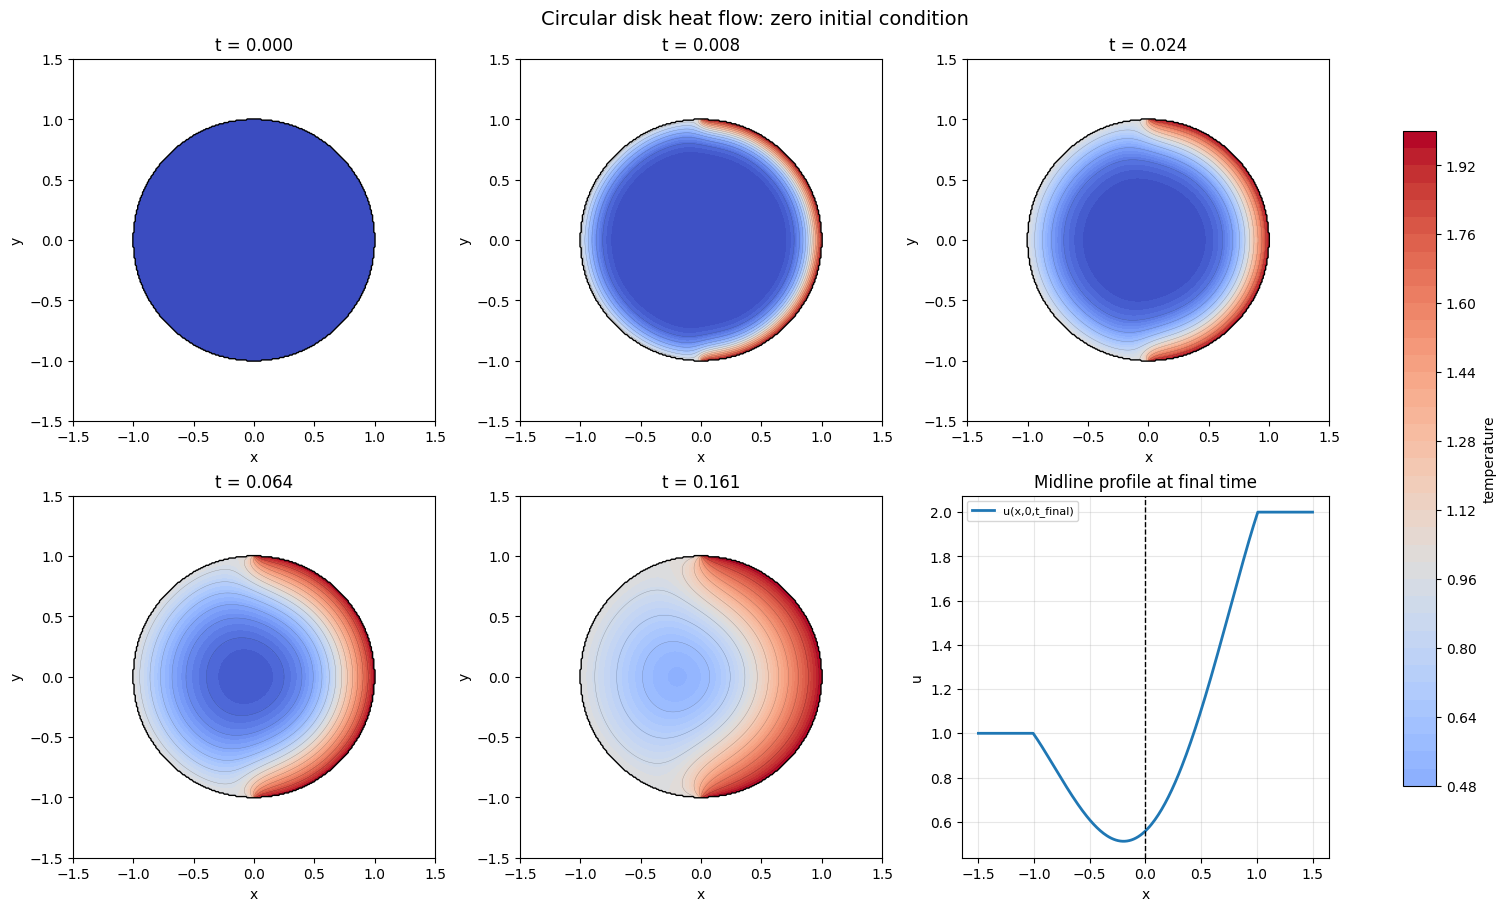

Final midline temperature range: 0.512 to 1.984
Left/right exterior bath values: 1.0, 2.0


In [8]:
# Case 1: zero initial condition inside the disk
snapshot_steps = [0, 400, 1200, 3200, 8000]
u0_zero = initial_zero()
snapshots_zero = simulate_heat(u0_zero, nsteps=snapshot_steps[-1], snapshot_steps=snapshot_steps)

plot_case(snapshots_zero, "Circular disk heat flow: zero initial condition")

final_zero = snapshots_zero[snapshot_steps[-1]]
mid_idx = np.argmin(np.abs(y - 0.0))
print(f"Final midline temperature range: {final_zero[mid_idx, inside[mid_idx]].min():.3f} to {final_zero[mid_idx, inside[mid_idx]].max():.3f}")
print(f"Left/right exterior bath values: {final_zero[outside & (X < 0)].min():.1f}, {final_zero[outside & (X >= 0)].max():.1f}")

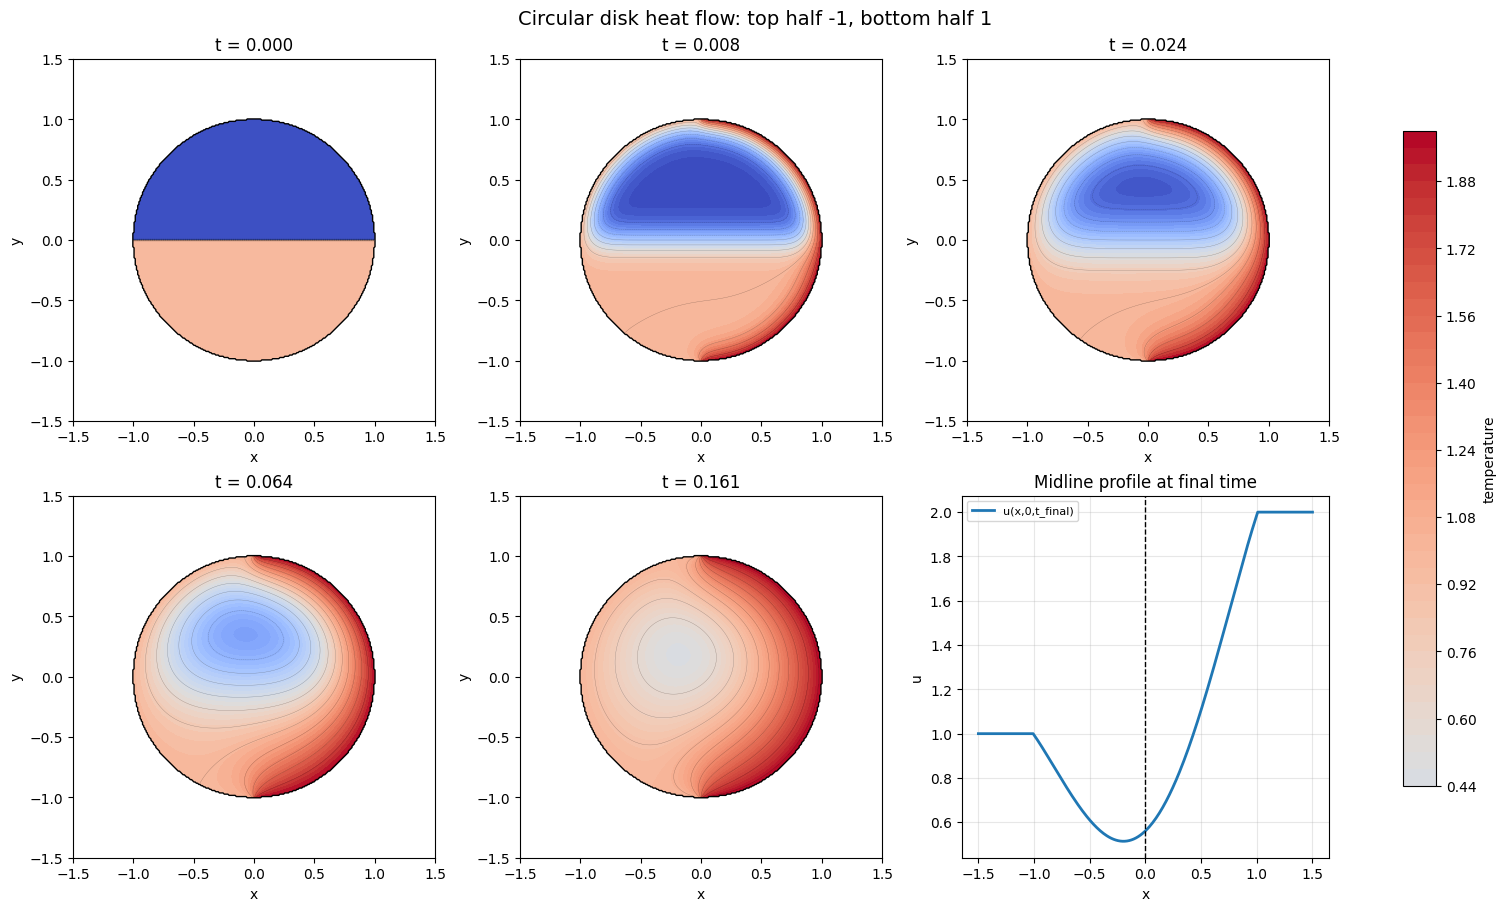

Final interior temperature range: 0.465 to 1.992
Mean interior temperature at final time: 1.084


In [9]:
# Case 2: top half starts at -1 and bottom half starts at 1 inside the disk
u0_signed = initial_top_bottom()
snapshots_signed = simulate_heat(u0_signed, nsteps=snapshot_steps[-1], snapshot_steps=snapshot_steps)

plot_case(snapshots_signed, "Circular disk heat flow: top half -1, bottom half 1")

final_signed = snapshots_signed[snapshot_steps[-1]]
print(f"Final interior temperature range: {final_signed[inside].min():.3f} to {final_signed[inside].max():.3f}")
print(f"Mean interior temperature at final time: {final_signed[inside].mean():.3f}")